# Pipeline de processamento e análise de imagem com OpenCV

Este notebook cobre os itens 1–6 e responde ao item 7. Execute as células na ordem. A imagem de entrada (`imagem_mercado.jpg`) deve estar na mesma pasta deste notebook. Para substituir a imagem, altere apenas `CAMINHO_IMAGEM`.

**Dependências:** `opencv-contrib-python`, `numpy` e `matplotlib`. O pacote contrib disponibiliza `cv2.SIFT_create()`.

Imagem de exemplo: *Fruit Stand*, fotografia de Francisco Anzola, via Wikimedia Commons; licença [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/).

Arquivo: /home/ubuntu/opencv_entrega/imagem_mercado.jpg
Dimensões (altura, largura, canais): (1362, 2048, 3)
Largura × altura: 2048 × 1362 px
Canais: 3; tipo: uint8; intervalo: 0–255


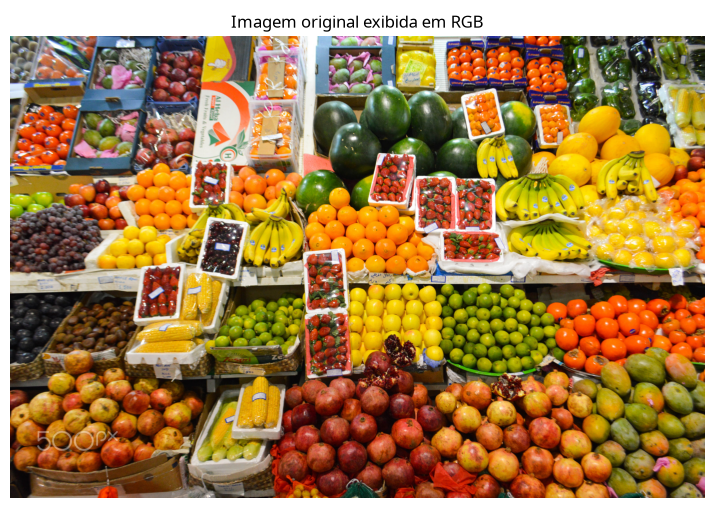

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

CAMINHO_IMAGEM = Path("imagem_mercado.jpg")
if not CAMINHO_IMAGEM.exists():
    # Facilita execução pelo Jupyter quando o diretório corrente é um nível acima.
    alternativa = Path("opencv_entrega") / CAMINHO_IMAGEM
    if alternativa.exists():
        CAMINHO_IMAGEM = alternativa

imagem_bgr = cv2.imread(str(CAMINHO_IMAGEM), cv2.IMREAD_COLOR)
if imagem_bgr is None:
    raise FileNotFoundError(f"Não foi possível carregar {CAMINHO_IMAGEM.resolve()}")
imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)
altura, largura, canais = imagem_bgr.shape
print(f"Arquivo: {CAMINHO_IMAGEM.resolve()}")
print(f"Dimensões (altura, largura, canais): {imagem_bgr.shape}")
print(f"Largura × altura: {largura} × {altura} px")
print(f"Canais: {canais}; tipo: {imagem_bgr.dtype}; intervalo: {imagem_bgr.min()}–{imagem_bgr.max()}")
plt.figure(figsize=(10, 6))
plt.imshow(imagem_rgb)
plt.title("Imagem original exibida em RGB")
plt.axis("off");


## 1. Leitura e caracterização

OpenCV carrega a fotografia em BGR por padrão. A conversão `BGR → RGB` é necessária para que `matplotlib` mostre as cores na ordem correta. Para esta imagem, o arranjo é `altura × largura × canais`; os pixels são inteiros sem sinal de 8 bits (`uint8`), no intervalo de 0 a 255.

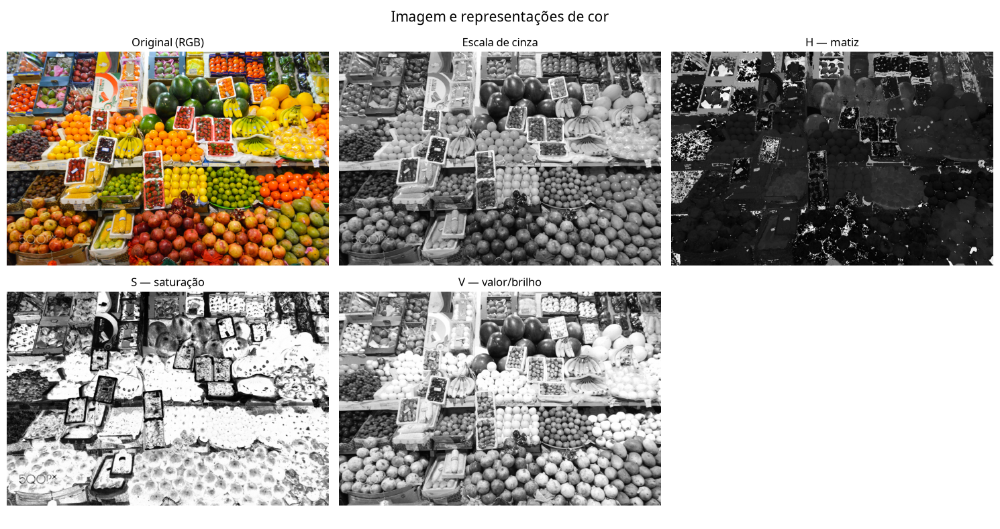

In [2]:
# 2. Conversão para grayscale e HSV, com separação explícita dos canais H, S e V.
imagem_cinza = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2GRAY)
imagem_hsv = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2HSV)
canal_h, canal_s, canal_v = cv2.split(imagem_hsv)

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
paineis = [
    (imagem_rgb, "Original (RGB)", None),
    (imagem_cinza, "Escala de cinza", "gray"),
    (canal_h, "H — matiz", "gray"),
    (canal_s, "S — saturação", "gray"),
    (canal_v, "V — valor/brilho", "gray"),
]
for ax, (dados, titulo, cmap) in zip(eixos.flat, paineis):
    ax.imshow(dados, cmap=cmap); ax.set_title(titulo); ax.axis("off")
eixos.flat[-1].axis("off")
fig.suptitle("Imagem e representações de cor", fontsize=15)
fig.tight_layout()


### Leitura dos canais

- **H (matiz):** codifica a família/categoria de cor, como vermelho, amarelo ou verde; regiões com cores diferentes tendem a contrastar.
- **S (saturação):** representa a intensidade/pureza da cor; valores baixos indicam tons mais acinzentados, e altos cores mais vivas.
- **V (valor):** representa o brilho, do escuro ao claro.
- **Grayscale:** resume cada pixel em intensidade luminosa; facilita observar luminosidade e estrutura, mas perde distinções de matiz.

Original: 2048 × 1362; reduzida: 1024 × 681


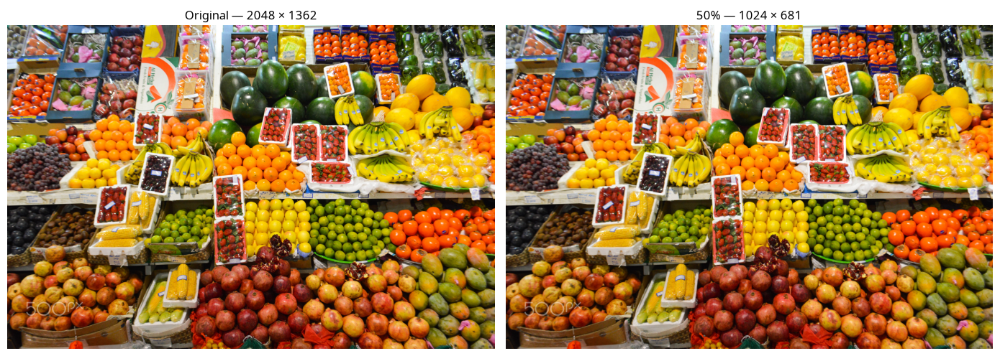

In [3]:
# 3. Metade da largura e da altura, calculadas a partir de image.shape.
nova_largura = max(1, int(largura * 0.5))
nova_altura = max(1, int(altura * 0.5))
imagem_reduzida = cv2.resize(imagem_rgb, (nova_largura, nova_altura), interpolation=cv2.INTER_AREA)
print(f"Original: {largura} × {altura}; reduzida: {nova_largura} × {nova_altura}")
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
eixos[0].imshow(imagem_rgb); eixos[0].set_title(f"Original — {largura} × {altura}")
eixos[1].imshow(imagem_reduzida); eixos[1].set_title(f"50% — {nova_largura} × {nova_altura}")
for ax in eixos: ax.axis("off")
fig.tight_layout()


## 3. Redimensionamento

A largura e a altura novas são calculadas diretamente de `imagem_bgr.shape`, sem dimensões fixadas manualmente. `INTER_AREA` é apropriado para redução e tende a minimizar artefatos de amostragem. A proporção é mantida.

Pontos de controle (origem → destino):
[245.8 163.4] → [327.7 217.9]
[1802.2  163.4] → [1761.3  299.6]
[ 245.8 1198.6] → [ 204.8 1144.1]
Matriz afim:
 [[ 9.211000e-01 -1.187000e-01  1.207242e+02]
 [ 5.250000e-02  8.947000e-01  5.878110e+01]]


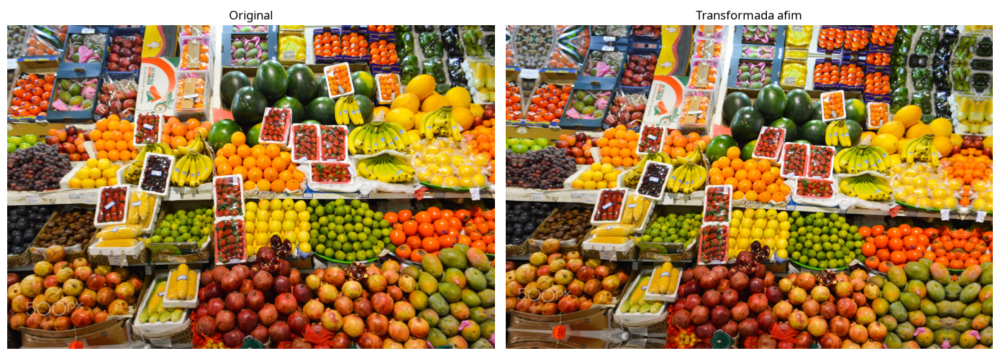

In [4]:
# 4. Transformação afim usando três pares de pontos proporcionais à imagem.
pontos_origem = np.float32([
    [0.12 * largura, 0.12 * altura],
    [0.88 * largura, 0.12 * altura],
    [0.12 * largura, 0.88 * altura],
])
pontos_destino = np.float32([
    [0.16 * largura, 0.16 * altura],
    [0.86 * largura, 0.22 * altura],
    [0.10 * largura, 0.84 * altura],
])
matriz_afim = cv2.getAffineTransform(pontos_origem, pontos_destino)
imagem_afim_bgr = cv2.warpAffine(
    imagem_bgr, matriz_afim, (largura, altura),
    flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT
)
imagem_afim_rgb = cv2.cvtColor(imagem_afim_bgr, cv2.COLOR_BGR2RGB)
imagem_afim_cinza = cv2.cvtColor(imagem_afim_bgr, cv2.COLOR_BGR2GRAY)
print("Pontos de controle (origem → destino):")
for origem, destino in zip(pontos_origem, pontos_destino):
    print(f"{origem.round(1)} → {destino.round(1)}")
print("Matriz afim:\n", np.round(matriz_afim, 4))
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
eixos[0].imshow(imagem_rgb); eixos[0].set_title("Original")
eixos[1].imshow(imagem_afim_rgb); eixos[1].set_title("Transformada afim")
for ax in eixos: ax.axis("off")
fig.tight_layout()


## 4. Transformação geométrica

Os três pontos de controle são definidos como proporções de `largura` e `altura`, portanto o código acompanha diferentes dimensões de entrada. Os pontos de destino introduzem uma deformação afim moderada. A imagem transformada mantém o tamanho do canvas original; `BORDER_REFLECT` preenche as áreas que, de outro modo, ficariam sem pixels válidos.

thresholds=(30, 60): 556,145 pixels de borda (19.94%)
thresholds=(80, 160): 271,934 pixels de borda (9.75%)
thresholds=(150, 250): 154,852 pixels de borda (5.55%)


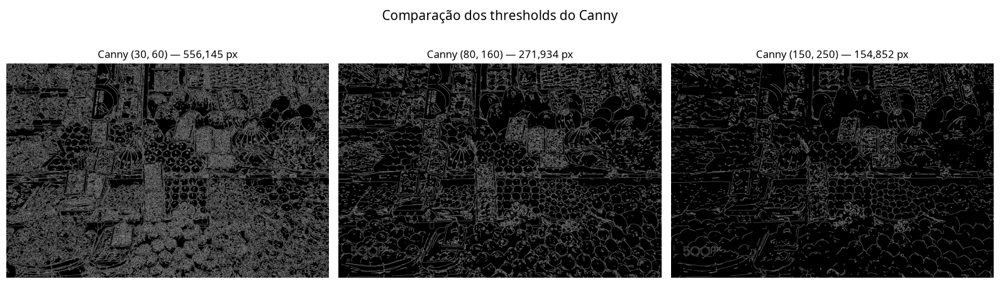

In [5]:
# 5. Canny: mesmas imagens em grayscale, três combinações de thresholds.
limiares = [(30, 60), (80, 160), (150, 250)]
resultados_canny = []
contagens_bordas = {}
for t1, t2 in limiares:
    bordas = cv2.Canny(imagem_cinza, t1, t2)
    resultados_canny.append(bordas)
    contagens_bordas[(t1, t2)] = int(np.count_nonzero(bordas))

fig, eixos = plt.subplots(1, 3, figsize=(16, 5))
for ax, bordas, (t1, t2) in zip(eixos, resultados_canny, limiares):
    qtd = contagens_bordas[(t1, t2)]
    print(f"thresholds=({t1}, {t2}): {qtd:,} pixels de borda ({100*qtd/(altura*largura):.2f}%)")
    ax.imshow(bordas, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Canny ({t1}, {t2}) — {qtd:,} px")
    ax.axis("off")
fig.suptitle("Comparação dos thresholds do Canny", fontsize=15)
fig.tight_layout()


## 5. Detecção de bordas

Canny usa um limiar inferior e outro superior: gradientes acima do limiar superior são aceitos como bordas fortes; os entre os limiares podem ser mantidos por histerese quando conectados a bordas fortes. Limiares mais baixos tendem a incluir mais contornos fracos e ruído; limiares mais altos tornam a detecção mais seletiva.

Keypoints SIFT — original: 17,434
Keypoints SIFT — afim: 18,854
Variação absoluta: +1420


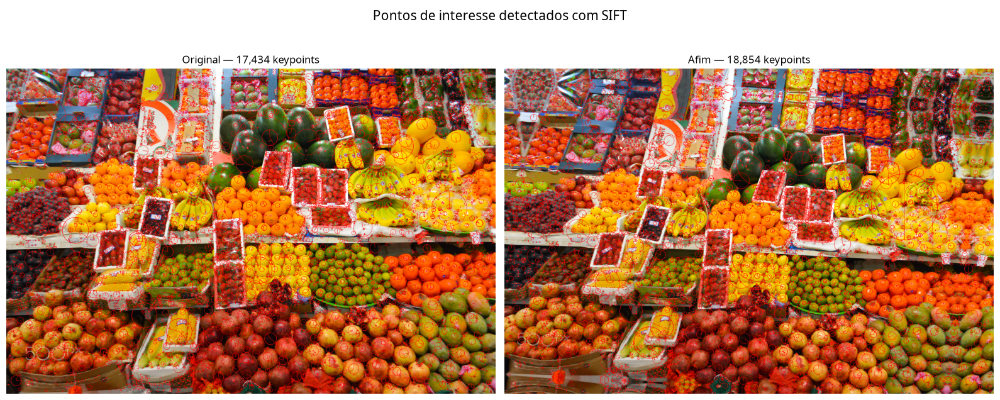

In [6]:
# 6. SIFT na imagem original e na transformada afim.
if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError("SIFT indisponível: instale opencv-contrib-python.")
sift = cv2.SIFT_create()
keypoints_original, descritores_original = sift.detectAndCompute(imagem_cinza, None)
keypoints_afim, descritores_afim = sift.detectAndCompute(imagem_afim_cinza, None)
print(f"Keypoints SIFT — original: {len(keypoints_original):,}")
print(f"Keypoints SIFT — afim: {len(keypoints_afim):,}")
print(f"Variação absoluta: {len(keypoints_afim)-len(keypoints_original):+d}")
visual_original = cv2.drawKeypoints(
    imagem_rgb, keypoints_original, None, color=(255, 0, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
visual_afim = cv2.drawKeypoints(
    imagem_afim_rgb, keypoints_afim, None, color=(255, 0, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
fig, eixos = plt.subplots(1, 2, figsize=(16, 7))
eixos[0].imshow(visual_original); eixos[0].set_title(f"Original — {len(keypoints_original):,} keypoints")
eixos[1].imshow(visual_afim); eixos[1].set_title(f"Afim — {len(keypoints_afim):,} keypoints")
for ax in eixos: ax.axis("off")
fig.suptitle("Pontos de interesse detectados com SIFT", fontsize=15)
fig.tight_layout()


## 7. Análise final

**a) Representação mais adequada para visualizar diferenças de cor.** O HSV é o mais adequado para separar e interpretar diferenças cromáticas: o canal H destaca a categoria de matiz, enquanto S separa cores vivas de cores pouco saturadas. RGB também mostra fielmente a aparência final, mas seus canais misturam efeitos de cor e iluminação; grayscale descarta a informação cromática. Para esta fotografia de frutas, as diferenças entre vermelhos, amarelos e verdes ficam particularmente interpretáveis em H/S.

**b) Efeito dos thresholds no Canny.** Ao aumentar os limiares, o detector rejeita gradientes mais fracos: os pixels classificados como borda caíram de **556.145 (19,94%)** em (30, 60), para **271.934 (9,75%)** em (80, 160), e **154.852 (5,55%)** em (150, 250). O primeiro resultado é mais denso e inclui detalhes/texturas finas; o último é mais esparso e seletivo, mantendo contornos mais fortes.

**c) Alteração na contagem de keypoints SIFT.** Sim: foram detectados **17.434** keypoints na imagem original e **18.854** na transformada afim, um aumento de **1.420** (aproximadamente 8,15%). A contagem pode variar com a imagem, versão do OpenCV e parâmetros do SIFT; os valores acima correspondem à execução deste notebook com a imagem fornecida.

**d) Permanência visual das regiões de interesse.** Em termos qualitativos, sim. Os keypoints continuam concentrados nas regiões texturizadas e com detalhes locais — frutas, bordas das caixas/embalagens e separações entre produtos —, embora sua posição na tela tenha sido deslocada/deformada junto com a imagem. Não se trata de uma correspondência ponto a ponto: interpolação, alteração dos gradientes, escala/orientação locais e preenchimento nas bordas mudam quais extremos do espaço-escala passam os critérios do SIFT. Assim, a distribuição por regiões visuais é semelhante, mas a quantidade e as coordenadas exatas não são invariantes.

### Fonte da imagem e declaração de uso de IA

Imagem: Francisco Anzola, *Fruit Stand*, disponibilizada no [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Fruit_Stand_(246046301).jpeg), licença [Creative Commons Atribuição 3.0 (CC BY 3.0)](https://creativecommons.org/licenses/by/3.0/). A imagem foi redimensionada e transformada neste exercício.

**Declaração de IA:** IA generativa foi utilizada como apoio na elaboração e revisão do código, na organização do notebook e na redação das análises. O processamento numérico, as figuras e as contagens foram produzidos pelo pipeline OpenCV executado sobre a imagem citada.